In [1]:
# Find the repo root (the folder containing src/paths.py), put src/ on the import
# path, and run from the repo root so relative data/ and calibration/ paths resolve.
import os, sys
_root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_root, "src", "paths.py")):
    _parent = os.path.dirname(_root)
    if _parent == _root:
        raise RuntimeError("Could not find src/paths.py above the working directory")
    _root = _parent
if os.path.join(_root, "src") not in sys.path:
    sys.path.insert(0, os.path.join(_root, "src"))
os.chdir(_root)

In [2]:
%load_ext autoreload
%autoreload 2

from plotting import *
from optimization_utils import smooth_inflow
from param_loader import METANET_Params

In [18]:
path_id = "i24_4hrs/i24_11_23"
data_path = f"data/{path_id}"
lanes = np.load(f"{data_path}/lane_mapping.npy")
i24_rho = np.load(f"{data_path}/rho_hat.npy") / lanes
i24_q = np.load(f"{data_path}/q_hat.npy")

T = 10/3600
l = 0.4
num_calibrated_segments = 14
downstream_density = smooth_inflow(i24_rho[:, -1])
data_inflow = smooth_inflow(i24_q[:, 0])

i24_rho = np.where(i24_rho == 0.0, 1e-3, i24_rho)
i24_q = np.where(i24_q == 0.0, 1e-3, i24_q)
i24_v = i24_q/(i24_rho * lanes)
init_traffic_state = (i24_rho[0, 1:-1], i24_v[0, 1:-1], data_inflow[0], 0)

## Plotting robustness curves

8
{6: '#4F8FCF', 12: '#002DF4', 30: '#5644FA', 60: '#8B59FF', 90: '#BB4EFF', 120: '#E45DFF', 180: '#FF5DBE', 360: '#FF5D5D'}


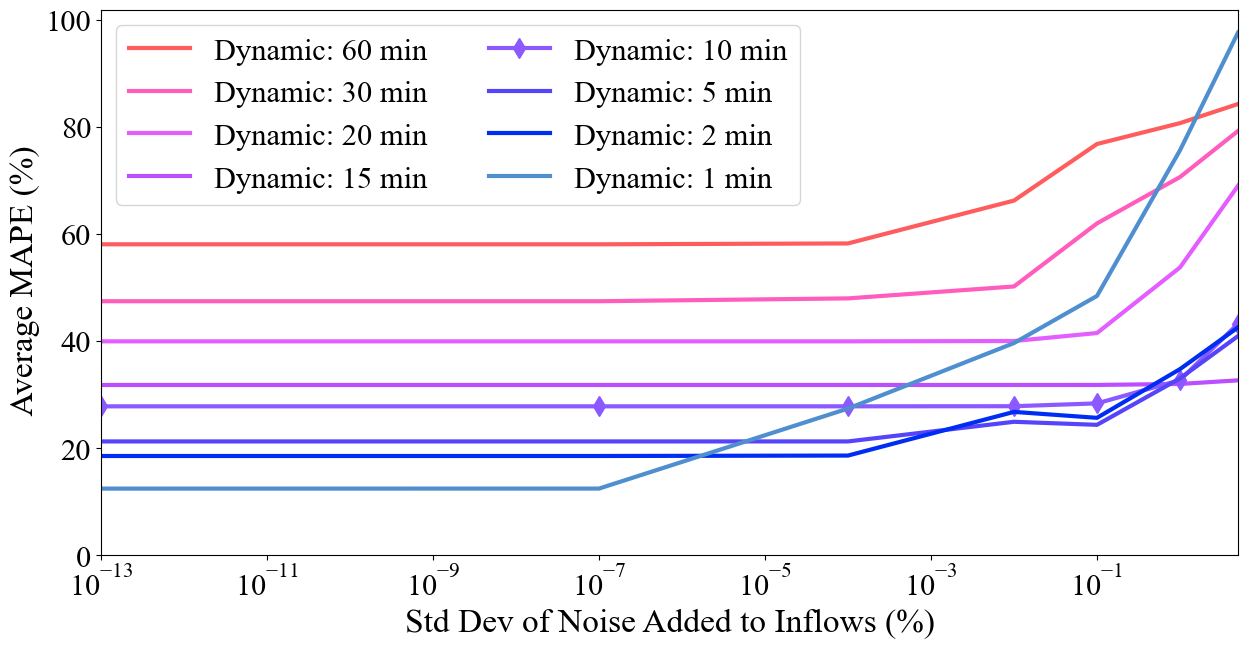

In [4]:
# root_dir = "cdc2026/synthetic_data_rain/mpc_calibration_results_var0.2"
root_dir = f"calibration/{path_id}" + "/calibration_dynamic_smooth" #"calibration/i24/i24_11_30/calibration_dynamic_smooth"
ch = [360, 180, 120, 90, 60, 30, 12, 6]
dir_to_plot = [f"{root_dir}/control_h_{c}" for c in ch] #["calibration/i24/i24_11_30/calibration_static/fixed_ramping"] + 
print(len(dir_to_plot))

plot_percentile_curves(dir_to_plot, desired_legend_order=[f"Dynamic: {int(c/6)} min" for c in ch], 
                       metric="mean", percentile=False, save_path=f"{root_dir}/figs", figname = "performance_plot.pdf", highlight_hor=[60])

{6: '#4F8FCF', 12: '#002DF4', 30: '#5644FA', 60: '#8B59FF', 90: '#BB4EFF', 120: '#E45DFF', 180: '#FF5DBE', 360: '#FF5D5D'}


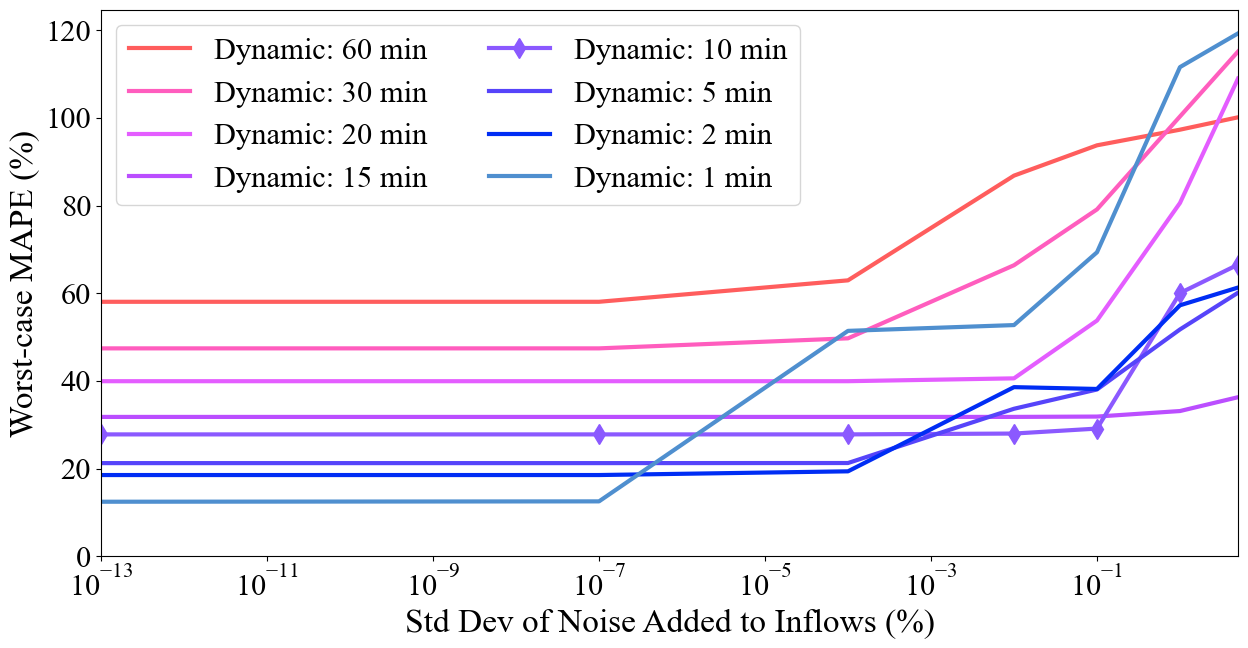

In [7]:
# # root_dir = "cdc2026/synthetic_data_rain/mpc_calibration_results_var0.2"
# root_dir = "calibration/i24/i24_11_30/calibration_dynamic_smooth"
# ch = [180, 120, 90, 60, 30, 12, 6]
# dir_to_plot = ["calibration/i24/i24_11_30/calibration_static/fixed_ramping"] + [f"{root_dir}/control_h_{c}" for c in ch]
# print(len(dir_to_plot))

plot_percentile_curves(dir_to_plot, desired_legend_order=[f"Dynamic: {int(c/6)} min" for c in ch], 
                       metric="max", percentile=False, save_path=f"{root_dir}/figs", 
                       figname = "performance_plot_worstcase.pdf", highlight_hor=[60])

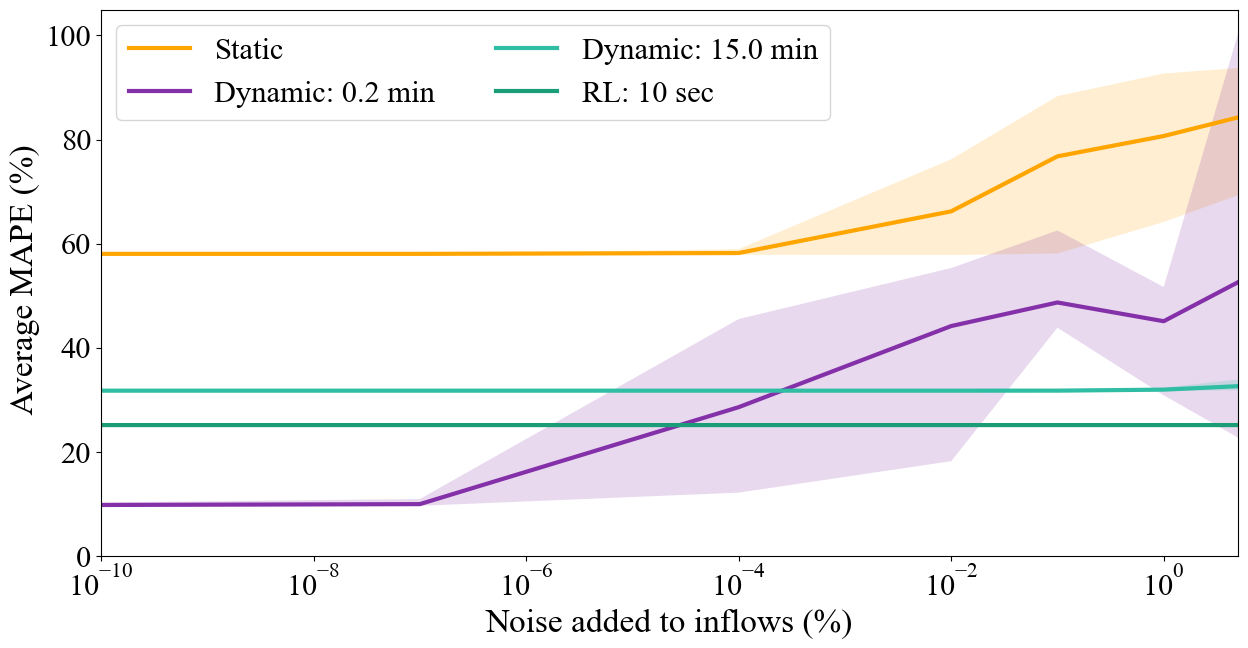

In [9]:
dir_to_plot = [f"calibration/{path_id}/calibration_static/fixed_ramping", 
               f"calibration/{path_id}/calibration_dynamic_smooth/control_h_1", 
               f"calibration/{path_id}/calibration_dynamic_smooth/control_h_90",  
               f"calibration/{path_id}/rl_calibration"]

plot_percentile_curves(dir_to_plot, desired_legend_order=["Static", "Dynamic: 0.2 min", "Dynamic: 15.0 min", "RL: 10 sec"], 
                       metric="mean", g_fontsize=24, percentile=True, horizon_decimals=1)

## Plotting perturbation curves

In [4]:
from eval_metrics import mape
from simulation_utils import run_metanet_sim


Config: OCP (calibration/i24/i24_11_30/calibration_static/fixed_ramping)
Segment: 0
Cache:  figs/itsc2026/smooth_landscape_plots/perturbation_cache/OCP_seg0_bc0_n20_pmin-0.0100_pmax0.0090.npz
  No cache found, running perturbations...
  Baseline MAPE: 58.0605
  Perturbing eta_high...
  Perturbing K...
  Perturbing tau...
  Perturbing p_crit...
  Perturbing v_free...
  Perturbing a...
  Saved perturbation data to: figs/itsc2026/smooth_landscape_plots/perturbation_cache/OCP_seg0_bc0_n20_pmin-0.0100_pmax0.0090.npz

Config: MPC_90 (calibration/i24/i24_11_30/calibration_dynamic_smooth/)
Segment: 0
Cache:  figs/itsc2026/smooth_landscape_plots/perturbation_cache/MPC_90_seg0_bc0_n20_pmin-0.0100_pmax0.0090.npz
  No cache found, running perturbations...
  Baseline MAPE: 31.8029
  Perturbing eta_high...
  Perturbing K...
  Perturbing tau...
  Perturbing p_crit...
  Perturbing v_free...
  Perturbing a...
  Saved perturbation data to: figs/itsc2026/smooth_landscape_plots/perturbation_cache/MPC_90_

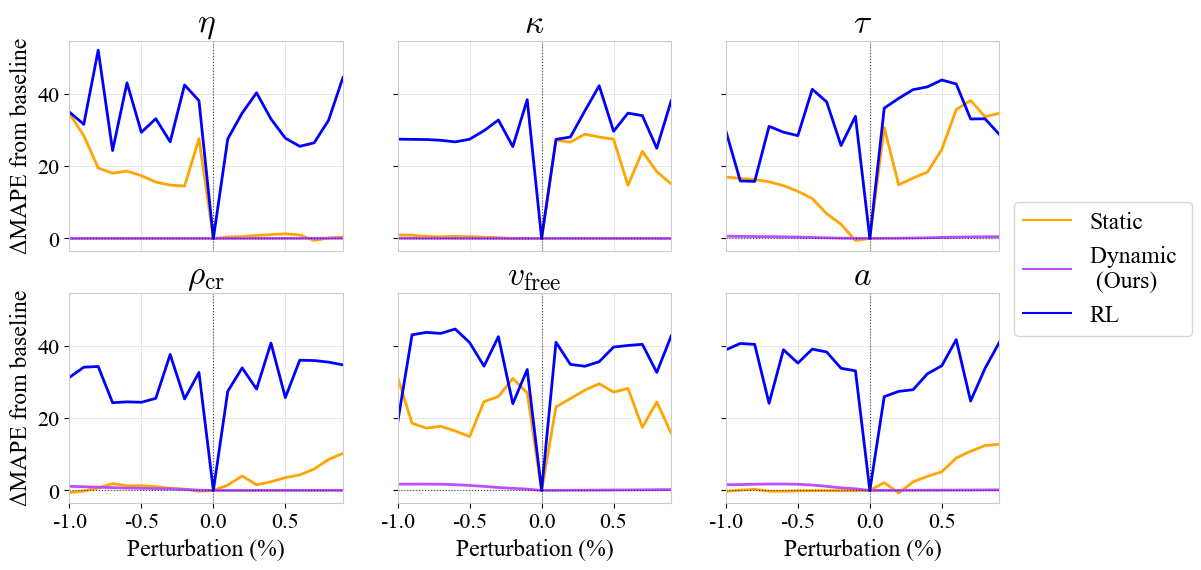


Saved plot to figs/itsc2026/smooth_landscape_plots/sensitivity_comparison_rl_segment0.pdf


<Figure size 640x480 with 0 Axes>

In [12]:
# Each config specifies its own lanes and preprocessing, matching standalone cells

seg = 0
param_configs = [
    {
        "label": "OCP",
        "results_dir": f"calibration/{path_id}/calibration_static/fixed_ramping",
        "control_hor": None,
        "lanes": lanes[1:-1],
        "smooth_rho": False,
        "smooth_bc": True,
        "segment_idx": seg,      # optional, defaults to 7
        "bc_timestep": 0,    # optional, defaults to 180
        "rho_hat": i24_rho,
        "q_hat": i24_q,
    },
    {
        "label": "MPC_90",
        "results_dir": f"calibration/{path_id}/calibration_dynamic_smooth/",
        "control_hor": 90,
        "lanes": lanes[1:-1],
        "smooth_rho": False,
        "smooth_bc": True,
        "segment_idx": seg,      # optional, defaults to 7
        "bc_timestep": 0,    # optional, defaults to 180
        "rho_hat": i24_rho,
        "q_hat": i24_q,
    },
    {
        "label": "RL",
        "results_dir": f"calibration/{path_id}/rl_calibration/",
        "control_hor": None,
        "lanes": lanes[1:-1],
        "smooth_rho": False,
        "smooth_bc": True,
        "segment_idx": seg,      # optional, defaults to 7
        "bc_timestep": 0,    # optional, defaults to 180
        "rho_hat": i24_rho,
        "q_hat": i24_q,
    }
]

all_results = run_and_plot_perturbations(
    param_configs=param_configs,
    T=T, l=l,
    num_calibrated_segments=num_calibrated_segments,
    run_metanet_sim=run_metanet_sim,
    perturb_pct=np.arange(-0.01, 0.01, 0.001),
    mape_fn=mape,
    save_path=f"figs/itsc2026/smooth_landscape_plots/sensitivity_comparison_rl_segment{seg}.pdf",
    cache_dir="figs/itsc2026/smooth_landscape_plots/perturbation_cache",
    use_cache=True,
    load_only=False,
    g_fontsize=16,
)


In [ ]:
time_param_configs = [
    {
        "label": "OCP",
        "results_dir": f"calibration/{path_id}/calibration_static/fixed_ramping",
        "control_hor": None,
        "lanes": lanes[1:-1],
        "smooth_rho": False,
        "smooth_bc": True,
        "segment_idx": "all",      # optional, defaults to 7
        "rho_hat": i24_rho,
        "q_hat": i24_q,
    },
    {
        "label": "MPC_90",
        "results_dir": f"calibration/{path_id}/calibration_dynamic_smooth/",
        "control_hor": 90,
        "lanes": lanes[1:-1],
        "smooth_rho": False,
        "smooth_bc": True,
        "segment_idx": "all",      # optional, defaults to 7
        "rho_hat": i24_rho,
        "q_hat": i24_q,
    },
    # {
    #     "label": "MPC_6",
    #     "results_dir": f"calibration/{path_id}/calibration_dynamic_smooth/",
    #     "control_hor": 6,
    #     "lanes": lanes[1:-1],
    #     "smooth_rho": False,
    #     "smooth_bc": True,
    #     "segment_idx": "all",      # optional, defaults to 7
    #     "rho_hat": i24_rho,
    #     "q_hat": i24_q,
    # },
]


Config: OCP (calibration/i24/i24_11_30/calibration_static/fixed_ramping)
Segment: all | delta=0.02 | window=30
Cache:  figs/smooth_landscape_plots/curvature_cache/OCP_curv_segall_d0.0200_w30.npz
  Loading existing curvature data...

Config: MPC_90 (calibration/i24/i24_11_30/calibration_dynamic_smooth/)
Segment: all | delta=0.02 | window=30
Cache:  figs/smooth_landscape_plots/curvature_cache/MPC_90_curv_segall_d0.0200_w30.npz
  Loading existing curvature data...

Config: MPC_6 (calibration/i24/i24_11_30/calibration_dynamic_smooth/)
Segment: all | delta=0.02 | window=30
Cache:  figs/smooth_landscape_plots/curvature_cache/MPC_6_curv_segall_d0.0200_w30.npz
  Loading existing curvature data...


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp



Saved plot to figs/smooth_landscape_plots/curvature_over_time.pdf


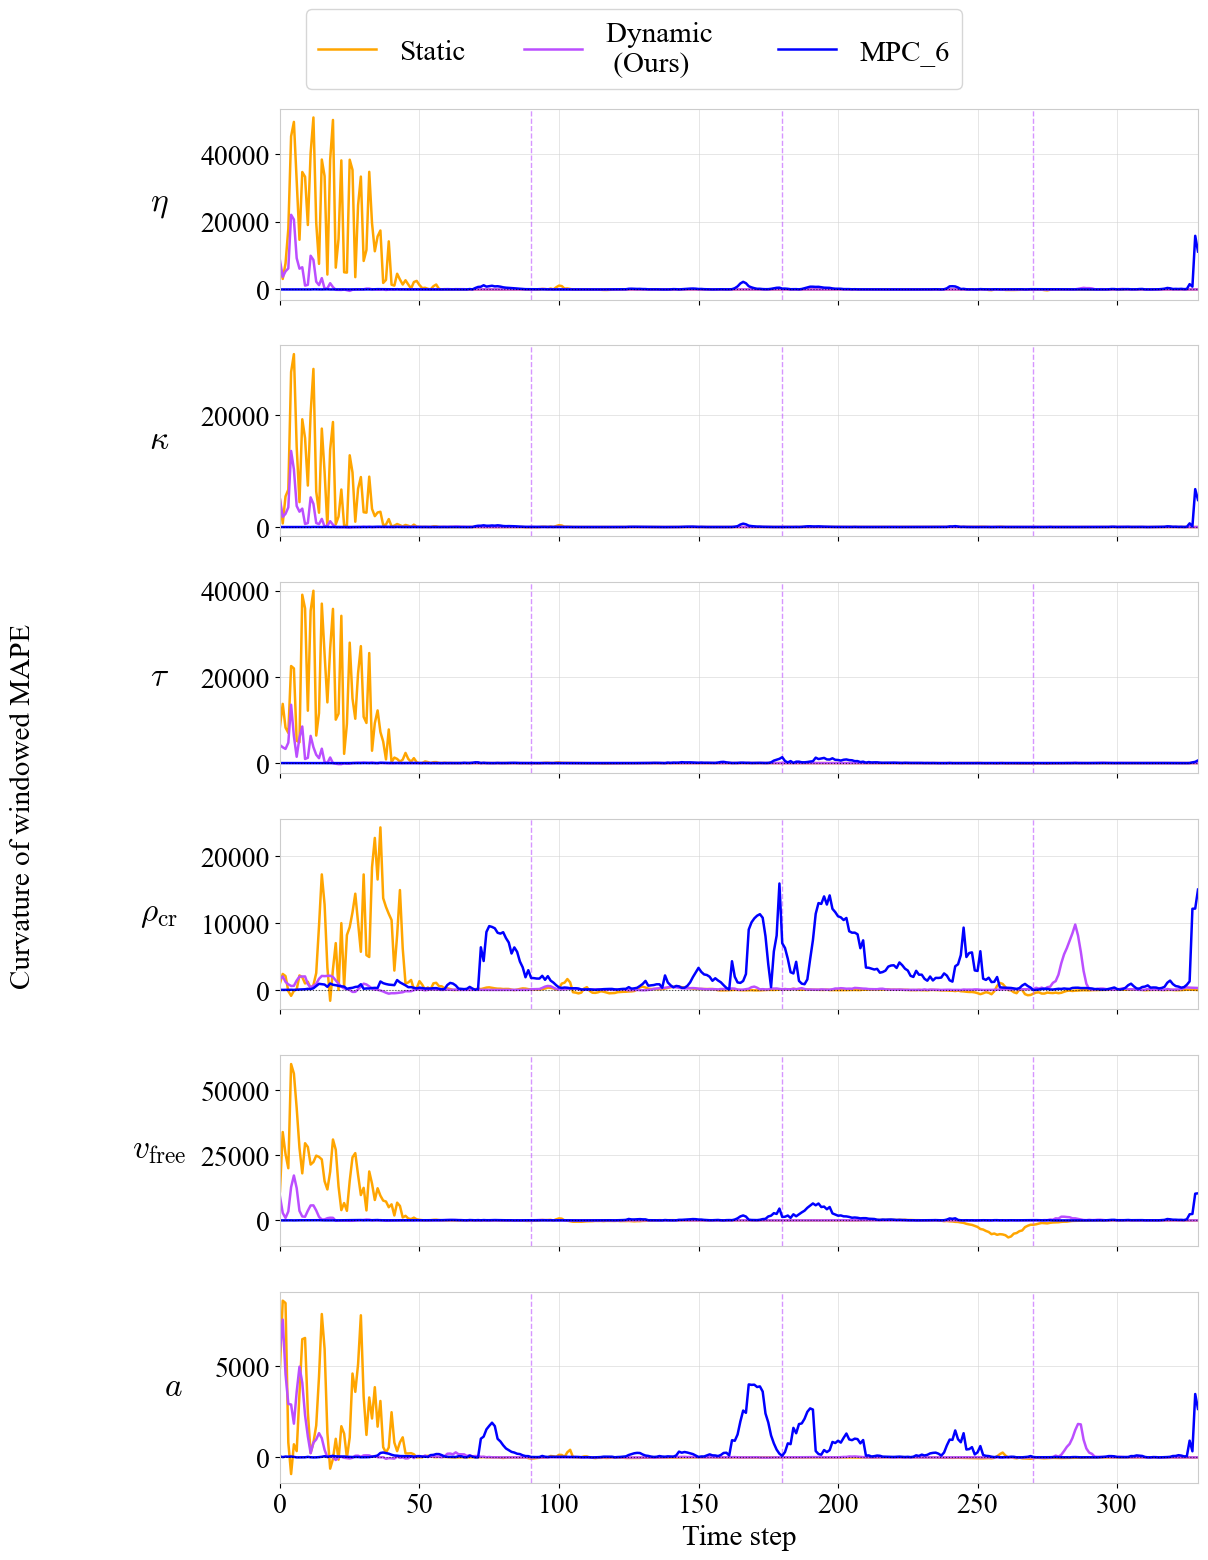

In [11]:
all_curv = run_and_plot_curvature_over_time(
    time_param_configs, T=T, l=l, num_calibrated_segments=num_calibrated_segments,
    run_metanet_sim=run_metanet_sim, mape_fn=mape,
    delta=0.02, window=30,
    save_path="figs/smooth_landscape_plots/curvature_over_time.pdf",
    cache_dir="figs/smooth_landscape_plots/curvature_cache",
)

## MPC Horizon comparison

## Time-space diagrams from noisy inflows

In [8]:
from eval_metrics import generate_perturbations

In [19]:
# Change these values to correspond to the appropriate paths / data
root_dir = f"calibration/{path_id}" + "/calibration_dynamic_smooth"
ga_root_dir = f"calibration/{path_id}" + "/ga_calibration/"
static_root_dir = f"calibration/{path_id}" + "/calibration_static/fixed_ramping"
horizons = [360]
# params = [METANET_Params(path=root_dir, num_segments=num_calibrated_segments, 
#                          num_timesteps=len(downstream_density),
#                          control_h=H).get_params() for H in horizons] +\
#         [METANET_Params(path=ga_root_dir).get_params()]
params = [METANET_Params(path=static_root_dir, num_segments=num_calibrated_segments,
                         num_timesteps=len(downstream_density)).get_params()]
        # [METANET_Params(path=f"calibration/{path_id}/calibration_dynamic_smooth", num_segments=num_calibrated_segments, num_timesteps=len(downstream_density), control_h=90).get_params()]+\
        # [METANET_Params(path=f"calibration/{path_id}/rl_calibration", num_segments=num_calibrated_segments).get_params()]
labels = ["Gradient-based \n(IPOPT)"]#, "Gradient-based \n(MPC) transfer", "Gradient-free \n(RL) transfer"]#["Static", "Dynamic \n(15 min)"]
percent_noise_list = [0.001, 0.01, 1]  # or whatever you want

In [20]:
data = {labels[i]: dict() for i in range(len(labels))}

for i in range(len(params)):
    param = params[i]
    rho_sim, v_sim, _, tts_sim = run_metanet_sim(
        T, 
        l, 
        init_traffic_state,
        data_inflow,
        downstream_density,
        param,
        vsl_speeds=None,
        lanes={i: lanes[1:-1][i] for i in range(num_calibrated_segments)},
        plotting=True,
        real_data=True
    )
    data[labels[i]]["v_sim"] = v_sim

In [21]:
# Dicts to hold results for each noise level

for k in range(len(params)):
    param = params[k]
    label = labels[k]

    for percent_noise in percent_noise_list:
        plotting_v_sim = None
        plotting_rho_sim = None
        worst_v_sim = None

        perturbs = generate_perturbations(data_inflow, percent_noise, num=50)
        for perturbed_conditions in perturbs:
            rho_sim_noise, v_sim_noise, _, tts_noise = run_metanet_sim(T,
                                        l,
                                        init_traffic_state,
                                        perturbed_conditions,
                                        downstream_density,
                                        param, 
                                        vsl_speeds=None,
                                        lanes={i: lanes[1:-1][i] for i in range(num_calibrated_segments)},
                                        plotting=True,
                                        real_data=True)
        
            error = mape(i24_v[:, 1:-1], v_sim_noise[0:-1, :])

            if worst_v_sim is None or error > worst_v_sim:
                plotting_v_sim = v_sim_noise
                plotting_rho_sim = rho_sim_noise
                worst_v_sim = error

        # Store outputs
        print(worst_v_sim)
        data[label][f"v_sim_noise_{percent_noise}"] = plotting_v_sim

40.83171308619332
41.39285409306958
49.93494049784283


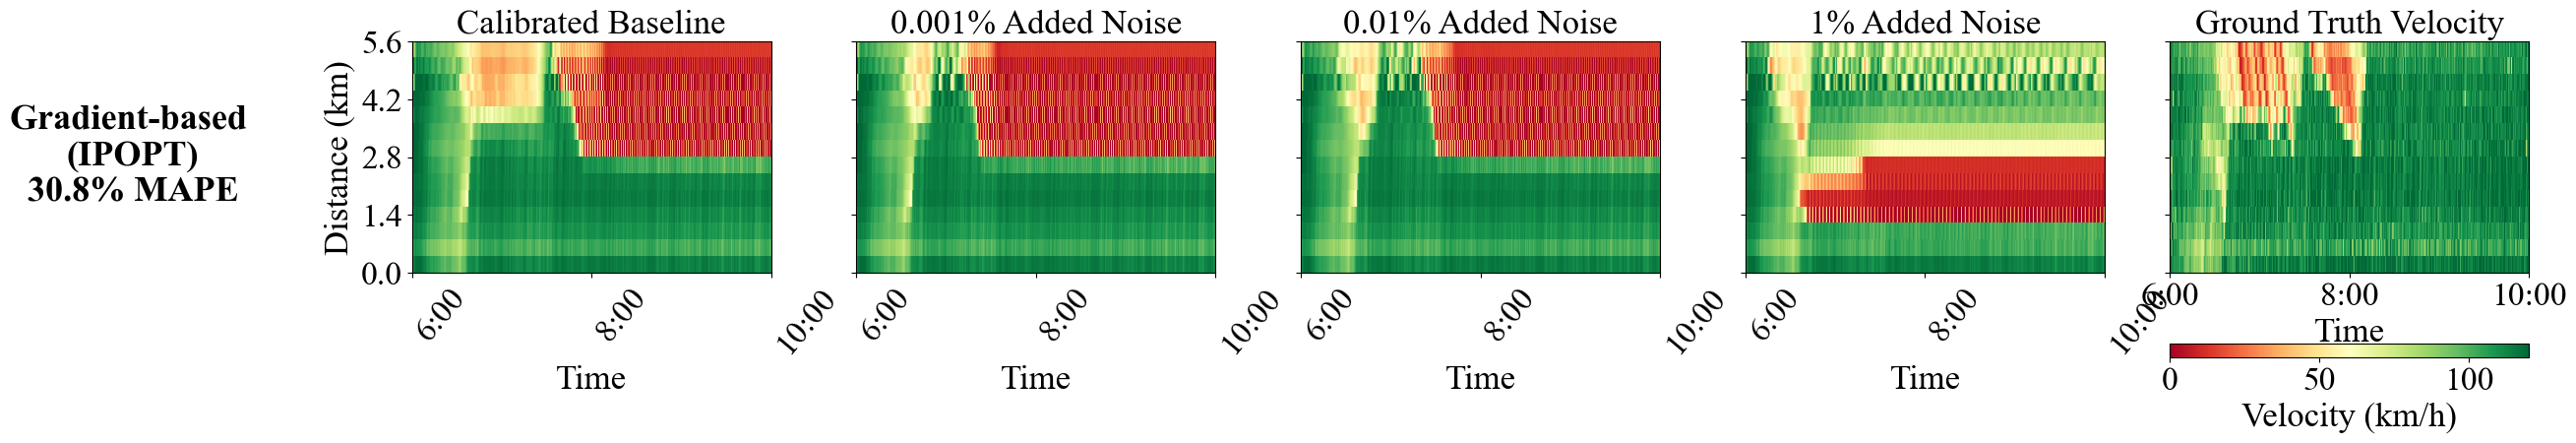

In [22]:
plot_time_space_grid(
    data=data,
    labels=labels,
    percent_noise_list=percent_noise_list,
    v_hat=i24_v,
    figsize_per_row=4,
    figsize_per_col=3.5,
    value_key_base="v_sim",
    vmin=0,
    vmax=120,
    cmap="RdYlGn",
    g_fontsize=24,
    colorbar_label="Velocity (km/h)",
    clean_title="Calibrated Baseline",
    vhat_title="Ground Truth Velocity",
    save_path="figs/4_hr_i24_noisy_inflows_11_23.png",
    show_gt=True,
    dt_seconds=10,
    start_time_str="06:00",
    x_tick_interval=120
)

## Fundamental diagram comparison

In [110]:
scenario = {
    "T": T,
    "l": l,
    "lanes": lanes[1:-1],
    "num_calibrated_segments": num_calibrated_segments,
    "rho_hat": i24_rho,
    "q_hat": i24_q,
    "init_traffic_state": init_traffic_state,
    "downstream_density": downstream_density,
    "data_inflow": data_inflow,
}

IsADirectoryError: [Errno 21] Is a directory: 'itsc_final/figs/static_fd.png'

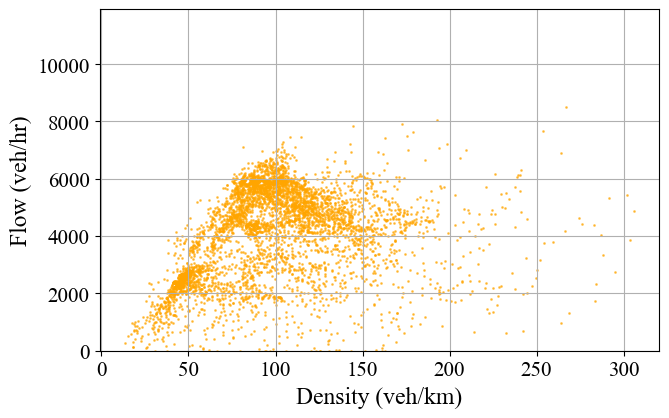

In [113]:
plot_fd_diagrams([METANET_Params(f"calibration/{path_id}/calibration_static/fixed_ramping").get_params()],
                  # METANET_Params(f"calibration/{path_id}/ga_calibration/trials2500").get_params(),
                  # METANET_Params(f"calibration/{path_id}/calibration_dynamic_smooth", control_h=90, num_timesteps=360).get_params()], 
                #   METANET_Params(f"calibration/{path_id}/rl_calibration").get_params()],
                 scenario_info=scenario,
                 labels=["Static (Gradient-based)"],#,  "Static (Gradient-free: GA)", "Dynamic (Gradient-based)"],
                 show_gt=False,
                 show_legend=False,
                 save_path="figs/itsc2026/static_fd.png") # "RL (10 sec)"])

## Cross-day evaluation
Simulate each calibration with the boundary conditions of every other weekday (11/24 and 11/25 are excluded as holidays) and compare speed MAPE on the training day with the average over the test days. Dynamic schedules are applied by time of day and calibrated ramp flows are reused as is, so this tests whether what was learned on the training day transfers.

In [10]:
from eval_metrics import evaluate_cross_day

train_day = path_id.split("/")[-1]   # e.g. "i24_11_30"
calib_root = f"calibration/{path_id}"
calibrations = {
    "Static": METANET_Params(f"{calib_root}/calibration_static/fixed_ramping"),
    "Dynamic (30 min)": METANET_Params(f"{calib_root}/calibration_dynamic_smooth", control_h=180, num_timesteps=360),
    "Dynamic (20 min)": METANET_Params(f"{calib_root}/calibration_dynamic_smooth", control_h=120, num_timesteps=360),
    "Dynamic (15 min)": METANET_Params(f"{calib_root}/calibration_dynamic_smooth", control_h=90, num_timesteps=360),
    "Dynamic (10 min)": METANET_Params(f"{calib_root}/calibration_dynamic_smooth", control_h=60, num_timesteps=360),
    "Dynamic (5 min)": METANET_Params(f"{calib_root}/calibration_dynamic_smooth", control_h=30, num_timesteps=360),
    "Dynamic (1 min)": METANET_Params(f"{calib_root}/calibration_dynamic_smooth", control_h=6, num_timesteps=360),
}
cross_day_results = evaluate_cross_day(calibrations, train_day=train_day)

In [13]:

cross_day_quantity = "v"    # "v" (speed) or "rho" (per-lane density)
cross_day_metric = "mape"   # which metric to show below: "mape" (%) or "rmse"
cross_day_results.pivot(index="day", columns="method", values=f"{cross_day_quantity}_{cross_day_metric}").round(1)

method,Dynamic (1 min),Dynamic (10 min),Dynamic (15 min),Dynamic (20 min),Dynamic (30 min),Dynamic (5 min),Static
day,,,,,,,
11_21,57.8,46.1,45.0,43.5,40.5,48.8,39.0
11_22,67.8,57.1,53.8,57.9,63.1,61.7,60.9
11_23,70.4,75.6,69.2,66.4,74.3,73.9,54.5
11_28,65.3,55.9,57.9,57.5,58.6,62.1,61.4
11_29,83.9,88.6,83.6,111.4,95.5,113.1,88.9
11_30,12.5,27.8,31.8,39.9,47.4,21.3,58.1
12_01,119.7,67.4,76.2,83.1,104.1,84.9,86.2
12_02,72.0,58.9,65.2,63.9,63.2,63.5,58.9


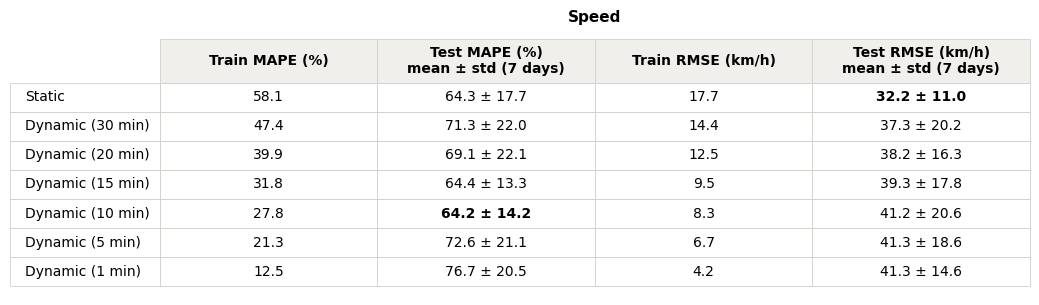

,Train MAPE (%),Test MAPE (%),Test MAPE (%) std
method,,,
Static,58.06,64.27,17.66
Dynamic (30 min),47.44,71.32,22.04
Dynamic (20 min),39.95,69.11,22.13
Dynamic (15 min),31.80,64.42,13.32
Dynamic (10 min),27.82,64.22,14.18
Dynamic (5 min),21.27,72.58,21.10
Dynamic (1 min),12.46,76.70,20.52


In [14]:
cross_day_summary = plot_cross_day_table(cross_day_results,
                                         save_path=f"figs/cross_day/{train_day}_cross_day_{cross_day_quantity}.pdf",
                                         quantity=cross_day_quantity, metric=cross_day_metric)
cross_day_summary.round(2)